In [1]:
!pip -q install scikit-optimize

from google.colab import drive
drive.mount('/content/drive')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 3.8 MB/s eta 0:00:00
Mounted at /content/drive


Dataset shape: (21263, 82)
Features: 81
Training samples: 14884
Validation samples: 3189
Test samples: 3190

Baseline Linear Regression
Validation: {'MAE': 13.580089101763532, 'MSE': 314.183730286108, 'RMSE': np.float64(17.725228638472), 'R2': 0.7315672235491866, 'Adjusted_R2': 0.7245691370050875}
Test: {'MAE': 13.268733023566337, 'MSE': 316.90044861521216, 'RMSE': np.float64(17.801697913828672), 'R2': 0.7246590090516889, 'Adjusted_R2': 0.7174831338049665}

Running Bayesian Optimization...
BO best alpha: 0.0001
BO validation RMSE: 17.725231381500773

Running Genetic Algorithm...
GA best alpha: 0.0001
GA validation RMSE: 17.725231381500773

Running Particle Swarm Optimization...
PSO best alpha: 0.0001
PSO validation RMSE: 17.725231381500773

========== OPTIMIZATION COMPARISON ==========
                     Method  Best_Alpha  Validation_RMSE  Optimization_Time_sec
      Bayesian Optimization      0.0001         17.72523               12.36762
          Genetic Algorithm      0.0001    

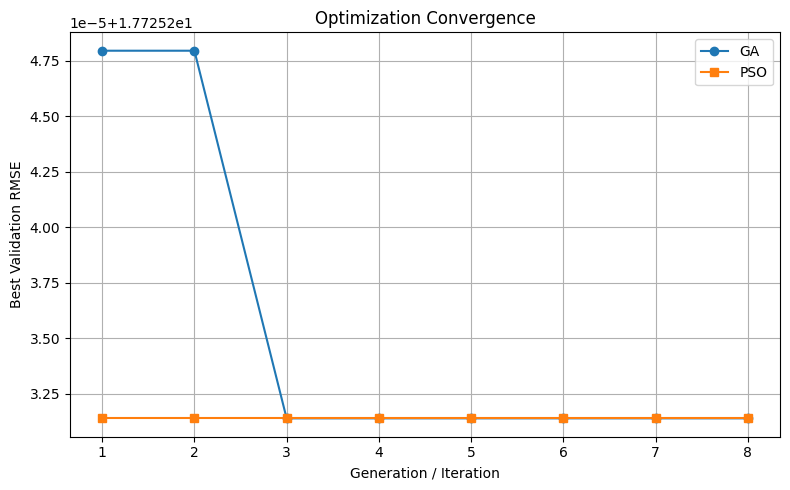

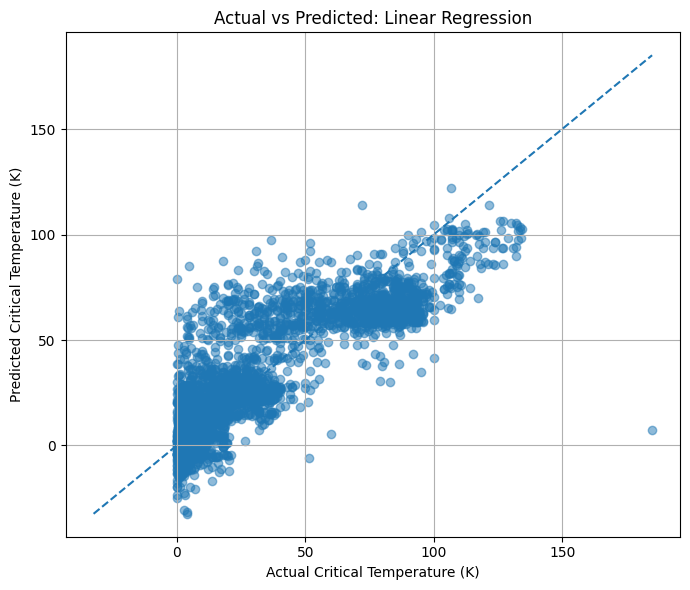


All output files saved in:
/content/drive/MyDrive/Optimized_Regression_Results

Files generated:
Linear_Regression_predictions.csv
Ridge_plus_BO_predictions.csv
Ridge_plus_GA_predictions.csv
Ridge_plus_PSO_predictions.csv
optimization_comparison.csv
final_model_comparison.csv
ga_history.csv
pso_history.csv
optimization_convergence.png
best_model_prediction_plot.png


In [2]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from skopt import gp_minimize
from skopt.space import Real

# ==================================================
# 1. LOAD DATASET
# ==================================================

DATA_PATH = "/content/drive/MyDrive/train.csv"
OUTPUT_DIR = "/content/drive/MyDrive/Optimized_Regression_Results"

os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
TARGET = "critical_temp"

df = pd.read_csv(DATA_PATH)

X = df.drop(columns=[TARGET])
y = df[TARGET]

# Remove rows with missing target
valid = y.notna()
X = X.loc[valid].reset_index(drop=True)
y = y.loc[valid].reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Features:", X.shape[1])

# ==================================================
# 2. TRAIN / VALIDATION / TEST SPLIT (70/15/15)
# ==================================================

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEED
)

# ==================================================
# 3. IMPUTATION AND SCALING
# Fit only on training data
# ==================================================

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_val = imputer.transform(X_val)
X_test = imputer.transform(X_test)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))

# ==================================================
# 4. EVALUATION FUNCTION
# ==================================================

def evaluate(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    n = len(y_true)
    p = X_train.shape[1]

    adjusted_r2 = (
        1 - (1 - r2) * (n - 1) / (n - p - 1)
        if n > p + 1 else np.nan
    )

    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2,
        "Adjusted_R2": adjusted_r2
    }

# ==================================================
# 5. BASELINE: ORDINARY LINEAR REGRESSION
# ==================================================

baseline = LinearRegression()

start = time.time()
baseline.fit(X_train, y_train)
baseline_time = time.time() - start

baseline_val_pred = baseline.predict(X_val)
baseline_test_pred = baseline.predict(X_test)

print("\nBaseline Linear Regression")
print("Validation:", evaluate(y_val, baseline_val_pred))
print("Test:", evaluate(y_test, baseline_test_pred))

# ==================================================
# 6. OBJECTIVE FUNCTION FOR OPTIMIZATION
# Optimize log10(alpha) using validation RMSE
# ==================================================

def objective(log_alpha):
    alpha = 10 ** float(np.asarray(log_alpha).ravel()[0])

    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    pred = model.predict(X_val)
    rmse = np.sqrt(mean_squared_error(y_val, pred))

    return float(rmse)

# Search alpha from 0.0001 to 100000
LOWER, UPPER = -4.0, 5.0

# ==================================================
# 7. BAYESIAN OPTIMIZATION (BO)
# ==================================================

print("\nRunning Bayesian Optimization...")
start = time.time()

bo_result = gp_minimize(
    func=objective,
    dimensions=[Real(LOWER, UPPER, name="log10_alpha")],
    n_calls=20,
    n_initial_points=6,
    acq_func="EI",
    random_state=SEED
)

bo_time = time.time() - start
bo_alpha = 10 ** bo_result.x[0]
bo_rmse = bo_result.fun

print("BO best alpha:", bo_alpha)
print("BO validation RMSE:", bo_rmse)

# ==================================================
# 8. GENETIC ALGORITHM (GA)
# ==================================================

def genetic_algorithm(
    population_size=8, generations=8, seed=42
):
    rng = np.random.default_rng(seed)

    population = rng.uniform(
        LOWER, UPPER, population_size
    )

    best_x = None
    best_score = float("inf")
    history = []

    def fitness(x):
        return objective([x])

    for generation in range(generations):
        scores = np.array([fitness(x) for x in population])

        idx = np.argmin(scores)

        if scores[idx] < best_score:
            best_score = scores[idx]
            best_x = population[idx]

        history.append(best_score)

        # Preserve the best candidate (elitism)
        new_population = [best_x]

        while len(new_population) < population_size:

            # Tournament selection
            candidates = rng.choice(
                population_size, size=3, replace=False
            )
            parent1 = population[
                candidates[np.argmin(scores[candidates])]
            ]

            candidates = rng.choice(
                population_size, size=3, replace=False
            )
            parent2 = population[
                candidates[np.argmin(scores[candidates])]
            ]

            # Crossover
            child = rng.uniform() * parent1 + (
                1 - rng.uniform()
            ) * parent2

            # Mutation
            if rng.random() < 0.3:
                child += rng.normal(0, 1.0)

            child = np.clip(child, LOWER, UPPER)
            new_population.append(child)

        population = np.array(new_population)

    return best_x, best_score, history


print("\nRunning Genetic Algorithm...")
start = time.time()

ga_log_alpha, ga_rmse, ga_history = genetic_algorithm(
    population_size=8,
    generations=8,
    seed=SEED
)

ga_time = time.time() - start
ga_alpha = 10 ** ga_log_alpha

print("GA best alpha:", ga_alpha)
print("GA validation RMSE:", ga_rmse)

# ==================================================
# 9. PARTICLE SWARM OPTIMIZATION (PSO)
# ==================================================

def particle_swarm(
    particles=8, iterations=8, seed=42
):
    rng = np.random.default_rng(seed)

    positions = rng.uniform(
        LOWER, UPPER, particles
    )
    velocities = rng.uniform(-0.5, 0.5, particles)

    personal_best = positions.copy()
    personal_scores = np.array([
        objective([x]) for x in positions
    ])

    best_idx = np.argmin(personal_scores)
    global_best = personal_best[best_idx]
    global_score = personal_scores[best_idx]

    history = []

    # PSO coefficients
    w = 0.7
    c1 = 1.5
    c2 = 1.5

    for iteration in range(iterations):
        for i in range(particles):

            r1 = rng.random()
            r2 = rng.random()

            velocities[i] = (
                w * velocities[i]
                + c1 * r1 * (personal_best[i] - positions[i])
                + c2 * r2 * (global_best - positions[i])
            )

            positions[i] += velocities[i]
            positions[i] = np.clip(
                positions[i], LOWER, UPPER
            )

            score = objective([positions[i]])

            if score < personal_scores[i]:
                personal_scores[i] = score
                personal_best[i] = positions[i]

            if score < global_score:
                global_score = score
                global_best = positions[i]

        history.append(global_score)

    return global_best, global_score, history


print("\nRunning Particle Swarm Optimization...")
start = time.time()

pso_log_alpha, pso_rmse, pso_history = particle_swarm(
    particles=8,
    iterations=8,
    seed=SEED
)

pso_time = time.time() - start
pso_alpha = 10 ** pso_log_alpha

print("PSO best alpha:", pso_alpha)
print("PSO validation RMSE:", pso_rmse)

# ==================================================
# 10. COMPARE OPTIMIZATION METHODS
# ==================================================

optimization_results = pd.DataFrame([
    {
        "Method": "Bayesian Optimization",
        "Best_Alpha": bo_alpha,
        "Validation_RMSE": bo_rmse,
        "Optimization_Time_sec": bo_time
    },
    {
        "Method": "Genetic Algorithm",
        "Best_Alpha": ga_alpha,
        "Validation_RMSE": ga_rmse,
        "Optimization_Time_sec": ga_time
    },
    {
        "Method": "Particle Swarm Optimization",
        "Best_Alpha": pso_alpha,
        "Validation_RMSE": pso_rmse,
        "Optimization_Time_sec": pso_time
    }
])

print("\n========== OPTIMIZATION COMPARISON ==========")
print(optimization_results.round(5).to_string(index=False))

# ==================================================
# 11. TRAIN FINAL RIDGE MODELS AND TEST
# Test data is not used for optimization
# ==================================================

models = {
    "Linear Regression": baseline,
    "Ridge + BO": Ridge(alpha=bo_alpha),
    "Ridge + GA": Ridge(alpha=ga_alpha),
    "Ridge + PSO": Ridge(alpha=pso_alpha)
}

all_metrics = []

for name, model in models.items():

    if name != "Linear Regression":
        model.fit(X_train, y_train)

    val_pred = model.predict(X_val)
    test_pred = model.predict(X_test)

    val_metrics = evaluate(y_val, val_pred)
    test_metrics = evaluate(y_test, test_pred)

    all_metrics.append({
        "Model": name,
        "Alpha": (
            np.nan if name == "Linear Regression"
            else model.alpha
        ),
        "Validation_RMSE": val_metrics["RMSE"],
        "Validation_R2": val_metrics["R2"],
        "Test_MAE": test_metrics["MAE"],
        "Test_MSE": test_metrics["MSE"],
        "Test_RMSE": test_metrics["RMSE"],
        "Test_R2": test_metrics["R2"],
        "Test_Adjusted_R2": test_metrics["Adjusted_R2"]
    })

    # Save predictions for each model
    pd.DataFrame({
        "Actual": y_test.to_numpy(),
        "Predicted": test_pred,
        "Residual": y_test.to_numpy() - test_pred
    }).to_csv(
        os.path.join(
            OUTPUT_DIR,
            name.replace(" ", "_").replace("+", "plus")
            + "_predictions.csv"
        ),
        index=False
    )

final_results = pd.DataFrame(all_metrics)

print("\n========== FINAL MODEL COMPARISON ==========")
print(final_results.round(5).to_string(index=False))

# ==================================================
# 12. SAVE RESULTS TO GOOGLE DRIVE
# ==================================================

optimization_results.to_csv(
    os.path.join(OUTPUT_DIR, "optimization_comparison.csv"),
    index=False
)

final_results.to_csv(
    os.path.join(OUTPUT_DIR, "final_model_comparison.csv"),
    index=False
)

# Save optimization convergence history
pd.DataFrame({
    "GA_Generation": range(1, len(ga_history) + 1),
    "GA_Best_Validation_RMSE": ga_history
}).to_csv(
    os.path.join(OUTPUT_DIR, "ga_history.csv"),
    index=False
)

pd.DataFrame({
    "PSO_Iteration": range(1, len(pso_history) + 1),
    "PSO_Best_Validation_RMSE": pso_history
}).to_csv(
    os.path.join(OUTPUT_DIR, "pso_history.csv"),
    index=False
)

# ==================================================
# 13. PLOT OPTIMIZATION CONVERGENCE
# ==================================================

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(ga_history) + 1),
    ga_history,
    marker="o",
    label="GA"
)
plt.plot(
    range(1, len(pso_history) + 1),
    pso_history,
    marker="s",
    label="PSO"
)

plt.xlabel("Generation / Iteration")
plt.ylabel("Best Validation RMSE")
plt.title("Optimization Convergence")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "optimization_convergence.png"),
    dpi=300
)
plt.show()

# Actual vs predicted plot for the best validation model
best_name = final_results.loc[
    final_results["Validation_RMSE"].idxmin(), "Model"
]
best_model = models[best_name]
best_pred = best_model.predict(X_test)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_pred, alpha=0.5)

low = min(y_test.min(), best_pred.min())
high = max(y_test.max(), best_pred.max())

plt.plot([low, high], [low, high], linestyle="--")
plt.xlabel("Actual Critical Temperature (K)")
plt.ylabel("Predicted Critical Temperature (K)")
plt.title(f"Actual vs Predicted: {best_name}")
plt.grid(True)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "best_model_prediction_plot.png"),
    dpi=300
)
plt.show()

print("\nAll output files saved in:")
print(OUTPUT_DIR)
print("\nFiles generated:")
for filename in os.listdir(OUTPUT_DIR):
    print(filename)